# Notebook 6 – Multivariate Analysis

Analyse relationships among **several variables at once**.

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet).
# This loader checks common local locations first, then tries the public source.
from pathlib import Path

TELCO_URLS = [
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/main/data/Telco-Customer-Churn.csv",
]

candidate_names = [
    "telco.csv",
    "Telco-Customer-Churn.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]

search_roots = [Path.cwd(), *list(Path.cwd().parents)[:4]]
local_candidates = []
for root in search_roots:
    for name in candidate_names:
        local_candidates.extend([
            root / name,
            root / "data" / name,
            root / "Datasets" / name,
            root / "dataset" / name,
        ])

local_path = next((p.resolve() for p in local_candidates if p.is_file()), None)

if local_path is not None:
    df_raw = pd.read_csv(local_path)
    print("Loaded local dataset:", local_path)
else:
    load_errors = []
    df_raw = None
    for url in TELCO_URLS:
        try:
            df_raw = pd.read_csv(url)
            print("Loaded dataset from public source.")
            break
        except Exception as exc:
            load_errors.append(f"{url} -> {type(exc).__name__}: {exc}")
    if df_raw is None:
        raise FileNotFoundError(
            "Could not find the Telco dataset locally, and downloading it failed. "
            "Place the original Telco Customer Churn CSV in a 'data' folder next to "
            "your notebooks (or in the parent folder's 'data' folder), name it "
            "'telco.csv' or 'Telco-Customer-Churn.csv', and rerun this cell. "
            "If using a URL, check your internet connection.\n\nDetails:\n"
            + "\n".join(load_errors)
        )

df = df_raw.copy()
print("Loaded:", df.shape)


# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


### Topic Explanation

A correlation heatmap uses colour to summarise pairwise correlation strengths and directions.

## 1. Correlation Matrix and Heatmap

### 1. Concept
A **correlation matrix** holds the pairwise Pearson correlations of numerical variables; a **heatmap** colours it. |r| ≥ 0.7 strong, 0.4–0.7 moderate, < 0.3 weak. Sign shows direction (negative = inverse).

### 2. Example
*Simple:* study hours, sleep hours and marks.  
*Business:* how tenure, price and total billing relate, and how they relate to churn.  
*AI/ML use:* find redundant features and promising predictors.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,ChurnFlag
tenure,1.00,0.25,0.83,0.02,-0.35
MonthlyCharges,0.25,1.00,0.65,0.22,0.19
TotalCharges,0.83,0.65,1.00,0.10,-0.20
SeniorCitizen,0.02,0.22,0.10,1.00,0.15
ChurnFlag,-0.35,0.19,-0.20,0.15,1.00


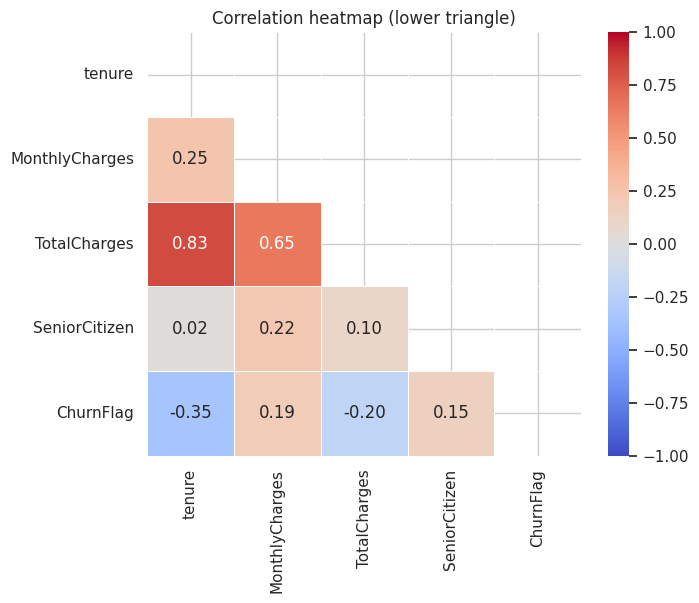

In [2]:
# include the binary target as 0/1 to see its (point-biserial) correlation with the numerics
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]
corr = df[corr_cols].corr()
display(corr.round(2))

plt.figure(figsize=(7, 5.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, mask=mask, linewidths=.5)
plt.title("Correlation heatmap (lower triangle)"); plt.show()

### 5. Interpretation
- **Strong positive:** `tenure`–`TotalCharges` (0.83).  
- **Moderate positive:** `MonthlyCharges`–`TotalCharges` (0.65).  
- **Weak positive:** `tenure`–`MonthlyCharges` (0.25), `SeniorCitizen`–`MonthlyCharges` (0.22).  
- **Negative with target:** `tenure`–`Churn` (≈ –0.35), `TotalCharges`–`Churn` (≈ –0.20).  
- **Weak positive with target:** `MonthlyCharges`–`Churn` (≈ 0.19).

### 6. Insight
Tenure has the strongest linear relationship with churn (negative: longer-staying customers churn less). `TotalCharges` correlates negatively with churn *only because* it grows with tenure.

### 7. AI/ML Relevance
Correlation with the target is a quick feature-importance proxy; correlations between features expose redundancy.

### Topic Explanation

This topic focuses on multicollinearity (vif). Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 2. Multicollinearity (VIF)

### 1. Concept
**Multicollinearity** is when predictors are strongly correlated with each other. It makes linear/logistic regression coefficients unstable. **VIF** (variance inflation factor) = 1 / (1 – R²) where R² comes from regressing a feature on the others. Rule of thumb: VIF > 5 (or 10) is a warning.

### 2. Example
*Simple:* using both height in cm and height in inches.  
*Business:* tenure, monthly price and total billing overlap in information.  
*AI/ML use:* drives feature selection for linear models (tree models are less affected).

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [3]:
def vif_table(data):
    X = data.dropna().astype(float)
    out = {}
    for c in X.columns:
        y = X[c].values
        A = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        resid = y - A @ beta
        r2 = 1 - resid.var() / y.var()
        out[c] = 1 / (1 - r2)
    return pd.Series(out, name="VIF").round(2)

print("VIF with all three numeric columns:")
display(vif_table(df[["tenure", "MonthlyCharges", "TotalCharges"]]).to_frame())
print("VIF after leaving out TotalCharges (what-if only, nothing is dropped):")
display(vif_table(df[["tenure", "MonthlyCharges"]]).to_frame())

VIF with all three numeric columns:


,VIF
tenure,5.84
MonthlyCharges,3.23
TotalCharges,9.53


VIF after leaving out TotalCharges (what-if only, nothing is dropped):


,VIF
tenure,1.07
MonthlyCharges,1.07


### 5. Interpretation
With `TotalCharges` included, its VIF (and that of `tenure`) is clearly above the usual threshold of 5, i.e. a *multicollinearity warning*. Without it, VIF falls to about 1.07 for both remaining features.

### 6. Insight
`TotalCharges` carries mostly the information of `tenure × MonthlyCharges`. If a linear model is chosen it is a candidate to drop or to replace with a ratio feature (e.g. average monthly spend).

### 7. AI/ML Relevance
High VIF inflates coefficient variance and makes interpretation unreliable; checking before modelling saves debugging time.

### Topic Explanation

A pair plot displays pairwise numeric relationships and individual-variable distributions in one view.

## 3. Pair Plot – Multiple Numerical Relationships

### 1. Concept
A **pair plot** shows all pairwise scatter plots and the distribution of each variable on the diagonal, optionally coloured by a category (here the target).

### 2. Example
*Simple:* a grid of mini scatter plots.  
*Business:* see if churners and non-churners separate in any combination of numeric features.  
*AI/ML use:* hints at separability, non-linearity, clusters and outliers.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

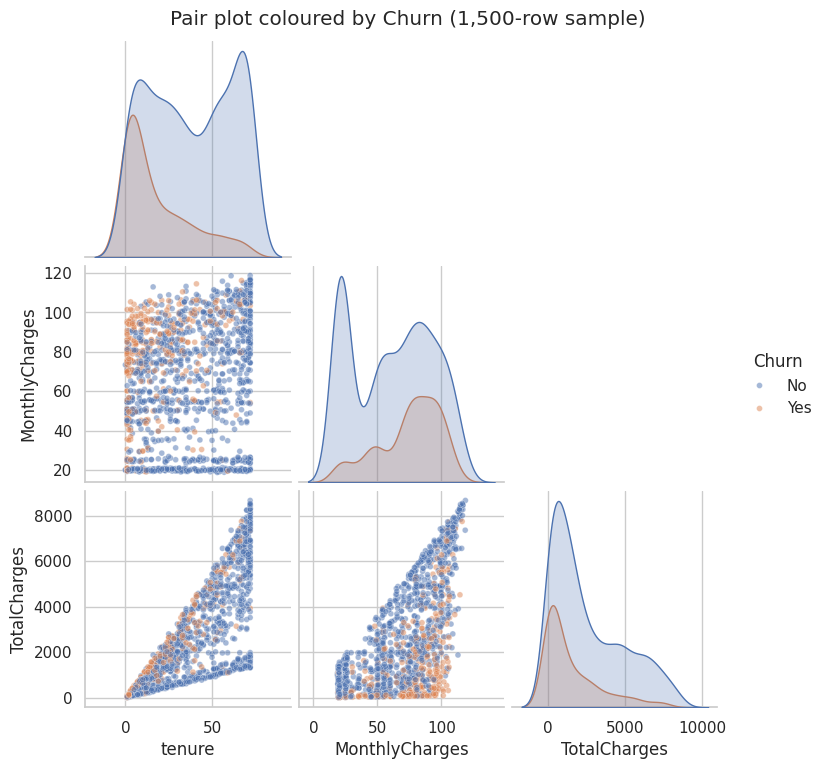

In [4]:
sample = df.sample(1500, random_state=1)   # sampling for speed/readability only
g = sns.pairplot(sample, vars=num_cols, hue="Churn", corner=True, plot_kws={"alpha": 0.5, "s": 18}, palette={"No": "#4c72b0", "Yes": "#dd8452"})
g.fig.suptitle("Pair plot coloured by Churn (1,500-row sample)", y=1.02); plt.show()

### 5. Interpretation
Churners (orange) concentrate at low tenure on every tenure panel and the diagonal KDE for churners peaks at small tenure. In the `tenure` × `MonthlyCharges` panel churners cluster at the upper-left (short tenure, high price). `TotalCharges` vs `tenure` forms a fan shape (the slope = monthly price).

### 6. Insight
No single numeric variable separates the classes perfectly; combining tenure and price is more informative than either alone → interactions matter.

### 7. AI/ML Relevance
The partial overlap suggests a non-trivial classifier (not a linear threshold on one variable) and shows that tree-based models/interaction features may help.

### Topic Explanation

This topic focuses on feature interactions. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 4. Feature Interactions

### 1. Concept
An **interaction** means the effect of one variable depends on another (e.g. contract type matters *more* for new customers). Explore with pivot tables / heatmaps of the target rate over two or three variables.

### 2. Example
*Simple:* a medicine works only in older patients.  
*Business:* month-to-month AND fibre AND electronic-check customers behave differently from the rest.  
*AI/ML use:* tells where engineered interaction features or tree models can add value.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

Contract,Month-to-month,One year,Two year
tenure_group,,,
0-12,51.4,10.5,0.0
13-24,37.7,8.1,0.0
25-48,32.9,10.6,2.2
49-72,26.0,12.9,3.3


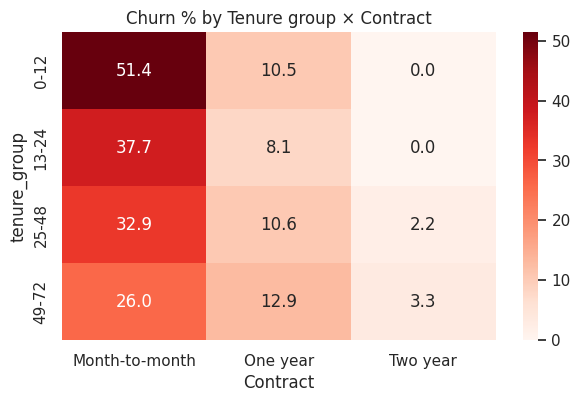

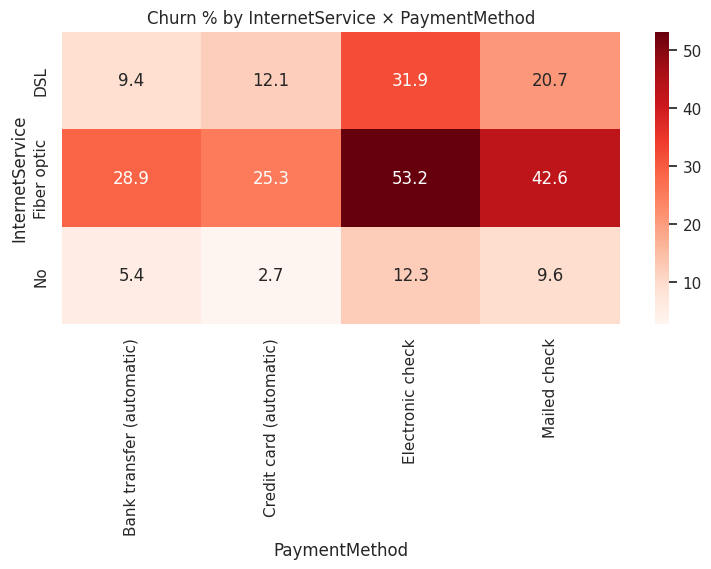

Month-to-month + Fiber + Electronic check: 1307 customers (18.6%), churn = 60.4%  vs overall 26.5%


In [5]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])

pivot = df.pivot_table(index="tenure_group", columns="Contract", values="ChurnFlag", aggfunc="mean", observed=False).mul(100).round(1)
display(pivot)
plt.figure(figsize=(7, 4)); sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds"); plt.title("Churn % by Tenure group × Contract"); plt.show()

pivot2 = df.pivot_table(index="InternetService", columns="PaymentMethod", values="ChurnFlag", aggfunc="mean").mul(100).round(1)
plt.figure(figsize=(9, 3.8)); sns.heatmap(pivot2, annot=True, fmt=".1f", cmap="Reds"); plt.title("Churn % by InternetService × PaymentMethod"); plt.show()

combo = df.query('Contract == "Month-to-month" and InternetService == "Fiber optic" and PaymentMethod == "Electronic check"')
print(f"Month-to-month + Fiber + Electronic check: {len(combo)} customers ({len(combo)/len(df):.1%}), churn = {combo.ChurnFlag.mean():.1%}  vs overall {df.ChurnFlag.mean():.1%}")

In [6]:
# number of add-on services vs churn (a created feature, for analysis)
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["n_addons"] = (df[addons] == "Yes").sum(axis=1)
(df.groupby("n_addons")["ChurnFlag"].agg(["mean", "count"]).assign(mean=lambda x: (x["mean"] * 100).round(1))
   .rename(columns={"mean": "churn_%"}))

,churn_%,count
n_addons,,
0,21.4,2219
1,45.8,966
2,35.8,1033
3,27.4,1118
4,22.3,852
5,12.4,571
6,5.3,284


### 5. Interpretation
- Churn is far higher for new customers on month-to-month contracts than for any other combination; long-tenure customers on two-year contracts almost never churn.  
- The risky segment *Month-to-month + Fibre + Electronic check* contains about 1,300 customers (≈ 19%) with a churn rate of ≈ 60% – more than double the overall rate (26.5%).  
- Churn falls as the number of protective add-ons grows (from ≈ 46% with 1 add-on to ≈ 5% with 6); customers with none are an exception because many of them have no internet at all.

### 6. Insight
The effects *compound*: risk factors multiply rather than add. Add-on services (support, security) appear to be associated with retention.

### 7. AI/ML Relevance
Interaction effects justify non-linear models (trees, boosting) or explicit interaction features; they also warn that single-feature analysis can understate risk.

## Findings Summary (Multivariate)

| Aspect | Finding |
|---|---|
| Strong correlation | `tenure`–`TotalCharges` (0.83) |
| Moderate | `MonthlyCharges`–`TotalCharges` (0.65) |
| Weak | `tenure`–`MonthlyCharges` (0.25) |
| Negative with churn | `tenure` (–0.35) |
| Multicollinearity | `TotalCharges` has VIF > 5 → redundant for linear models |
| Interesting interaction | Month-to-month × Fibre × Electronic check → ~60% churn |
| Protective factors | More add-on services (esp. security, support) → lower churn |